# Análises gráficas de Imigração do Ajuntamento de Terrassa-ES
Fonte dos dados públicos acessados em Novembro/2026: https://data.europa.eu/data/datasets/https-opendata-terrassa-cat-dataset-immigracions-per-mes-lloc-de-procedencia-i-sexe?locale=en

In [23]:
import pandas as pd
from matplotlib import pyplot as plt
from plotly import graph_objects as go
import seaborn as sns


In [2]:
df = pd.read_csv('spain.csv', sep= ';')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20845 entries, 0 to 20844
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   DATA_REFERENCIA        20845 non-null  int64 
 1   MES                    20845 non-null  int64 
 2   PAIS_PROCEDENCIA       20845 non-null  object
 3   PROVINCIA_PROCEDENCIA  10208 non-null  object
 4   SEXE                   20845 non-null  object
 5   POBLACIO               20845 non-null  int64 
dtypes: int64(3), object(3)
memory usage: 977.2+ KB


In [3]:
print(df.sample(5))

       DATA_REFERENCIA  MES PAIS_PROCEDENCIA PROVINCIA_PROCEDENCIA  SEXE  \
17269             2024    1    ARGENTINA, L'                   NaN  Dona   
10471             2018   12          ESPANYA               GRANADA  Dona   
17716             2024    4          ESPANYA                MÁLAGA  Dona   
17824             2024    5          ESPANYA                BURGOS  Home   
2924              2013    4        ÍNDIA, L'                   NaN  Home   

       POBLACIO  
17269         8  
10471         2  
17716         1  
17824         1  
2924          1  


In [4]:
new_col_names = []
for old_name in df.columns:
    name_stripped = old_name.strip()
    name_lowered = name_stripped.lower()
    new_col_names.append(name_lowered)
df.columns = new_col_names


In [5]:
df["data"] = pd.to_datetime(
    df["data_referencia"].astype(str) + "-" +
    df["mes"].astype(str).str.zfill(2) + "-01",
    format="%Y-%m-%d"
)

Dados inicialmente tratados.</br>
Alterei o nome das colunas deixando minúsculo e acrescentei a coluna 'data' com mês/ano agregados.</br>
A coluna 'poblacio' não faz sentido para mim, não sei qual foi a intenção de ser criada.

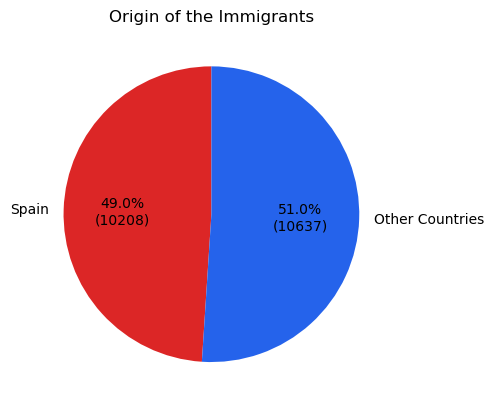

In [6]:
from_spain = df[df['pais_procedencia'] == 'ESPANYA']
out_spain = df[df['pais_procedencia'] != 'ESPANYA']

values = [from_spain['pais_procedencia'].count(), out_spain['pais_procedencia'].count()]
legends = ['Spain', 'Other Countries']

plt.pie(values, labels=legends, colors=["#DC2626", "#2563EB"], autopct=lambda p: f'{p:.1f}%\n({p*sum(values)/100:.0f})', startangle=90)
plt.title('Origin of the Immigrants')
plt.show()

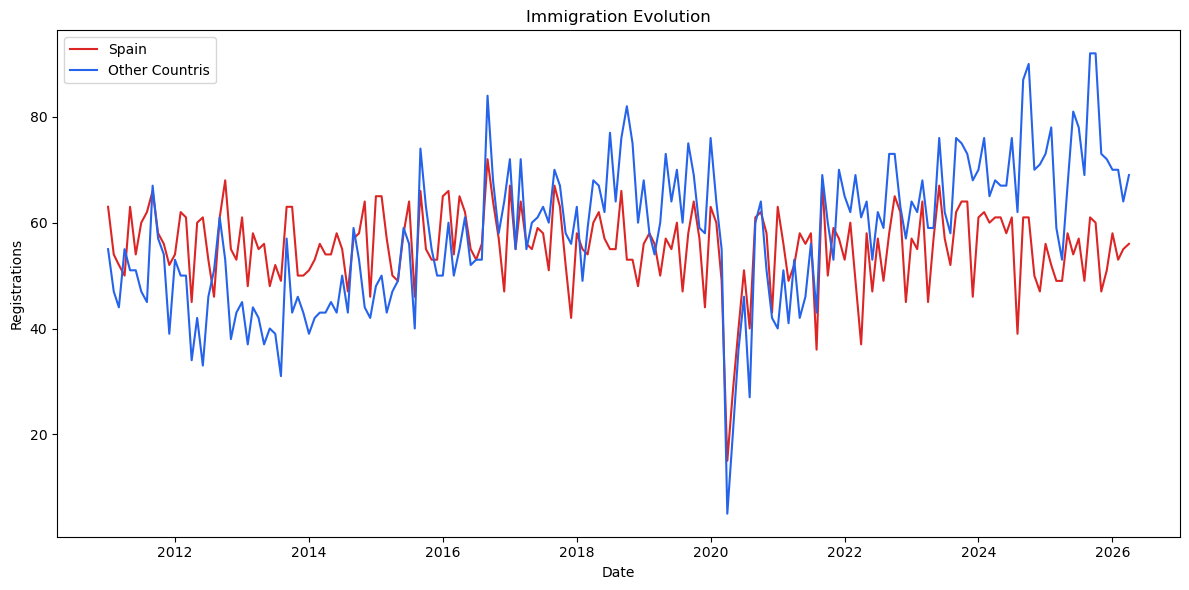

In [7]:
from_spain_1 = from_spain.groupby('data').size()
out_spain_1 = out_spain.groupby('data').size()

plt.figure(figsize=(12,6))

plt.plot(from_spain_1.index, from_spain_1.values, label='Spain', color='#DC2626')
plt.plot(out_spain_1.index, out_spain_1.values, label='Other Countris', color='#2563EB')

plt.title('Immigration Evolution')
plt.xlabel('Date')
plt.ylabel('Registrations')
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
top_provincias = from_spain.groupby('provincia_procedencia').size().sort_values(ascending=False).head(10)
top_countries = out_spain.groupby('pais_procedencia').size().sort_values(ascending=False).head(10)

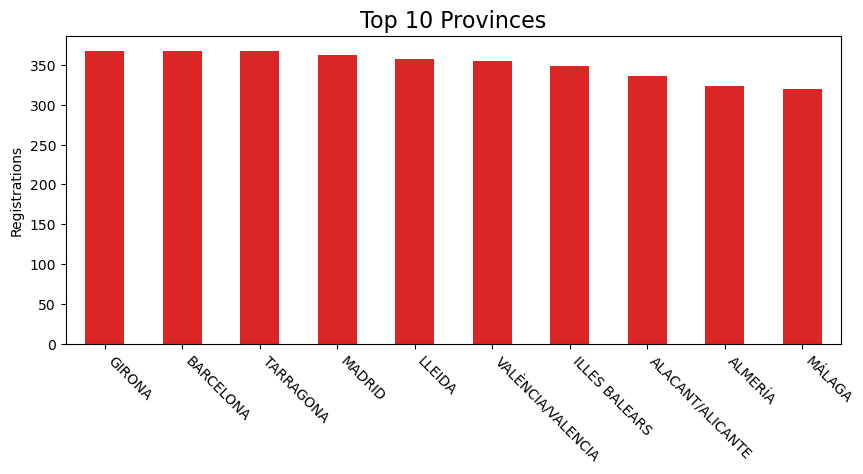

In [9]:
top_provincias.plot(kind='bar', color='#DC2626', figsize=(10,4), xlabel='', ylabel='Registrations')
plt.xticks(rotation=-45, ha='left')
plt.title('Top 10 Provinces', fontsize=16)
plt.show()

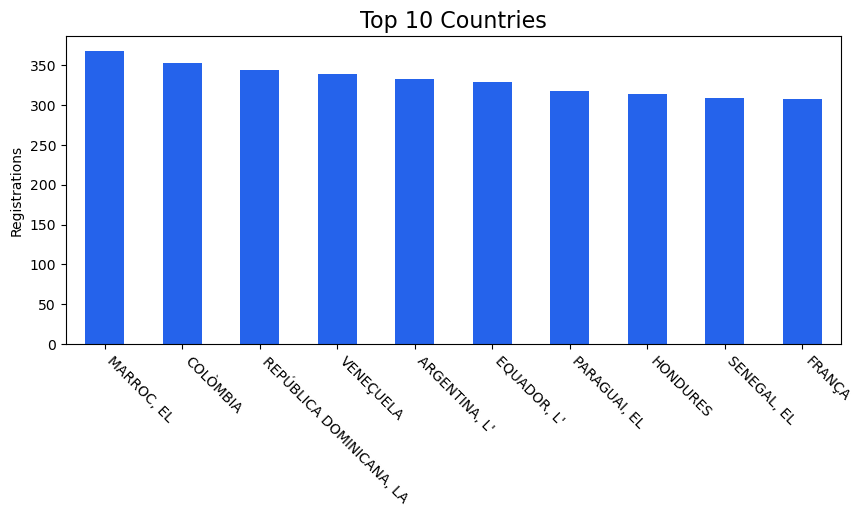

In [10]:
top_countries.plot(kind='bar', color='#2563EB', figsize=(10,4), ylabel='Registrations', xlabel='')
plt.xticks(rotation=-45, ha='left')
plt.title('Top 10 Countries', fontsize=16)
plt.show()

In [43]:
top_countries_1 = out_spain[out_spain['pais_procedencia'].isin(top_countries.index)].groupby(['data_referencia','pais_procedencia']).size().reset_index(name='qtd')
top_provincias_1 = from_spain[from_spain['provincia_procedencia'].isin(top_provincias.index)].groupby(['data_referencia','provincia_procedencia']).size().reset_index(name='qtd')


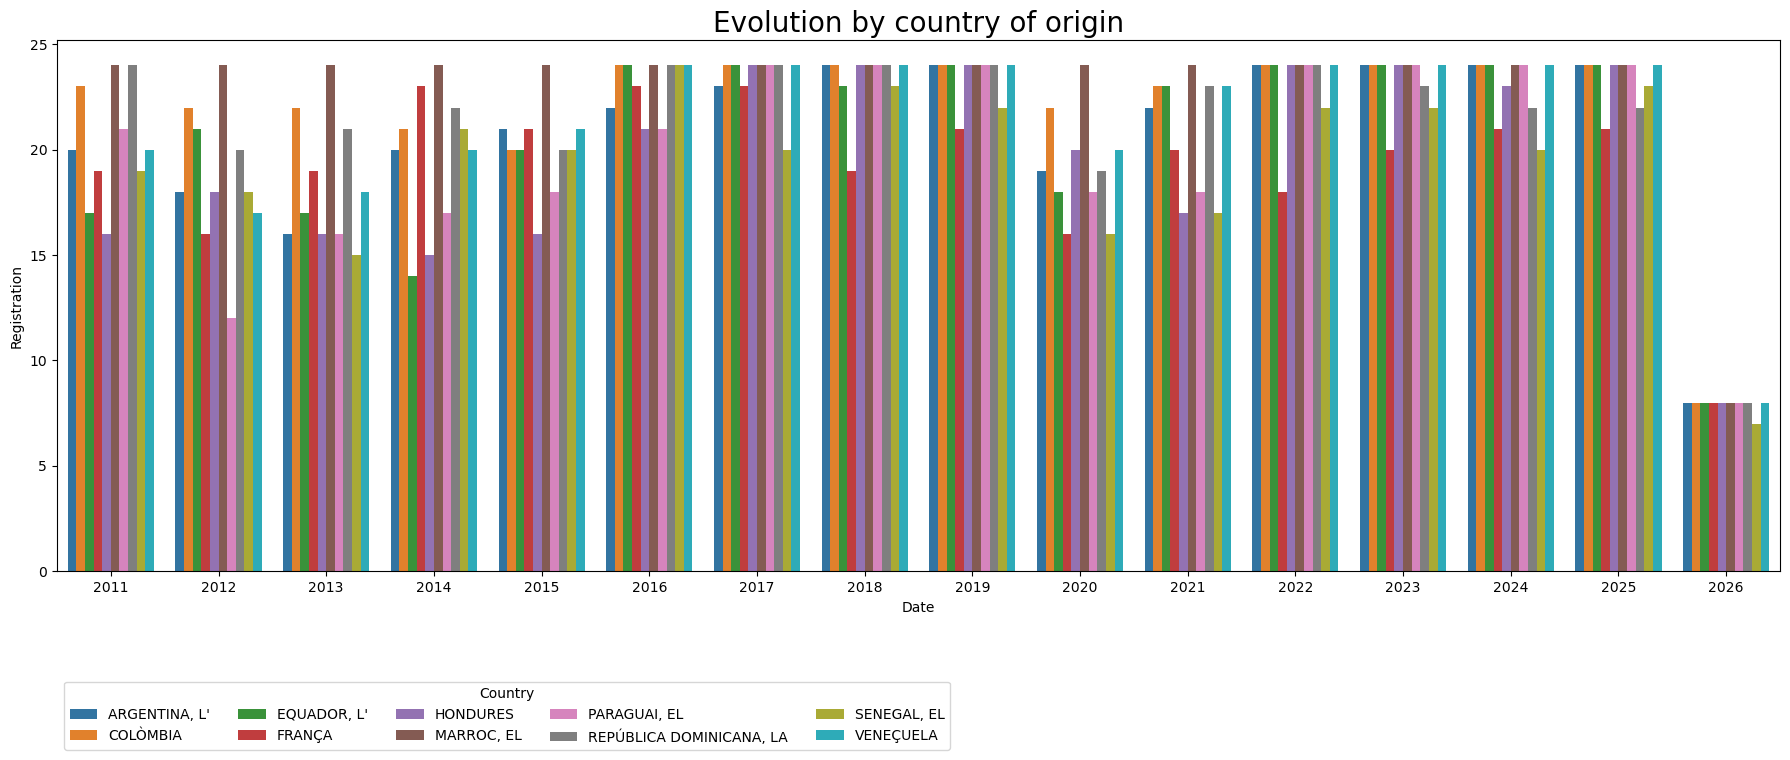

In [46]:
plt.figure(figsize=(18, 8))

sns.barplot(
    data=top_countries_1,
    x='data_referencia',
    y='qtd',
    hue='pais_procedencia'
)

plt.title('Evolution by country of origin', fontsize=20)
plt.xlabel('Date')
plt.ylabel('Registration')
plt.legend(
    title='Country',
    loc='lower left',
    bbox_to_anchor=(0, -0.35),
    ncol=5)
plt.tight_layout()

plt.show()

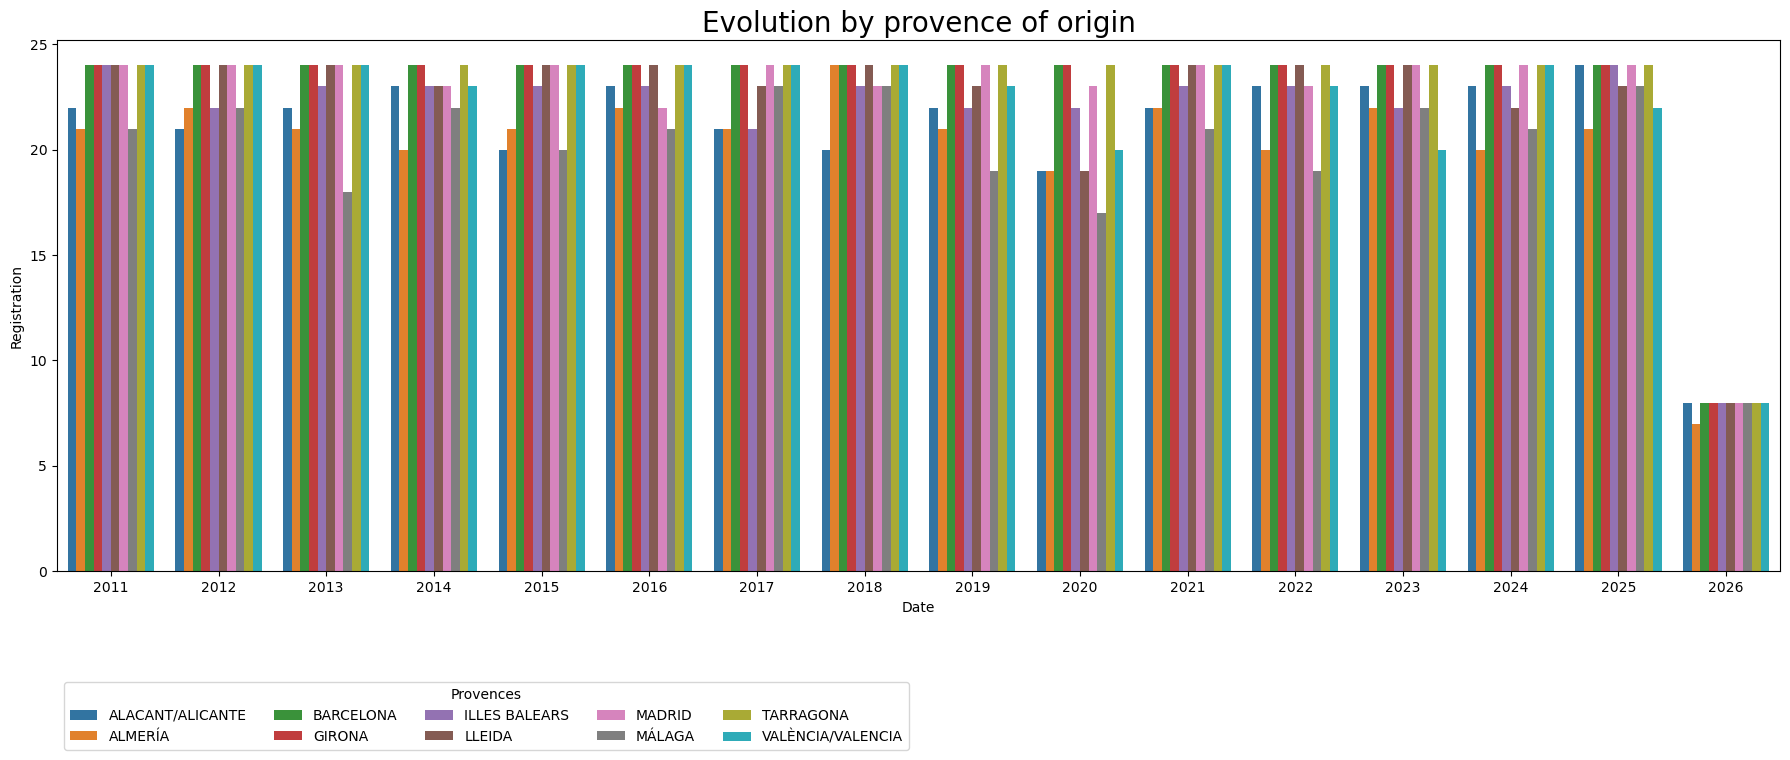

In [47]:
plt.figure(figsize=(18, 8))

sns.barplot(
    data=top_provincias_1,
    x='data_referencia',
    y='qtd',
    hue='provincia_procedencia'
)

plt.title('Evolution by provence of origin', fontsize=20)
plt.xlabel('Date')
plt.ylabel('Registration')
plt.legend(
    title='Provences',
    loc='lower left',
    bbox_to_anchor=(0, -0.35),
    ncol=5)
plt.tight_layout()

plt.show()

# Conclusão
Como vimos desde o primeiro gráfico, a Espanha compete em igualdade no quesito imigração para o Ajuntamento de Terrassa.</br>
Até 10 anos atrás, os outros países imigravam bem menos quando comparados ao restante da Espanha. Mas essa interpretação mudou a partir de 2016 se intensificando a cada ano.</br>
Os números voltaram a ficar próximos durante as restrições de fronteiras devido à Pandemia do Covid-19, mas já em 2022 os outros países retornaram a migrar fortemente para Terrassa.</br>
Quanto aos países que mais imigraram, a expectativa era que fossem países que tem o mesmo idioma nativo. Do Top-10, 7 são países latinos. Mas a maior surpresa é que o primeiro lugar como país que mais imigrou para Terrassa foi o africano Marrocos.</br>
Assim como vemos no gráfico seguinte, Marrocos tem uma boa regularidade em imigração ao longo dos anos.</br>
Quanto as províncias, temos Barcelona que é a província de Terrassa em segundo lugar, ficando atrás de Girona e a frete de Tarragona.